Make sure your dataset is placed in the data/ folder. Error details: Text.set() got an unexpected keyword argument 'fontweigh'
['Wind speed (m/s)', 'Wind speed, Standard deviation (m/s)', 'Wind speed, Minimum (m/s)', 'Wind speed, Maximum (m/s)', 'Long Term Wind (m/s)', 'Wind speed Sensor 1 (m/s)', 'Wind speed Sensor 1, Standard deviation (m/s)', 'Wind speed Sensor 1, Minimum (m/s)', 'Wind speed Sensor 1, Maximum (m/s)', 'Wind speed Sensor 2 (m/s)', 'Wind speed Sensor 2, Standard deviation (m/s)', 'Wind speed Sensor 2, Minimum (m/s)', 'Wind speed Sensor 2, Maximum (m/s)', 'Density adjusted wind speed (m/s)', 'Wind direction (°)', 'Nacelle position (°)', 'Wind direction, Standard deviation (°)', 'Wind direction, Minimum (°)', 'Wind direction, Maximum (°)', 'Nacelle position, Standard deviation (°)', 'Nacelle position, Minimum (°)', 'Nacelle position, Maximum (°)', 'Vane position 1+2 (°)', 'Vane position 1+2, Max (°)', 'Vane position 1+2, Min (°)', 'Vane position 1+2, StdDev (°)', 'Energy

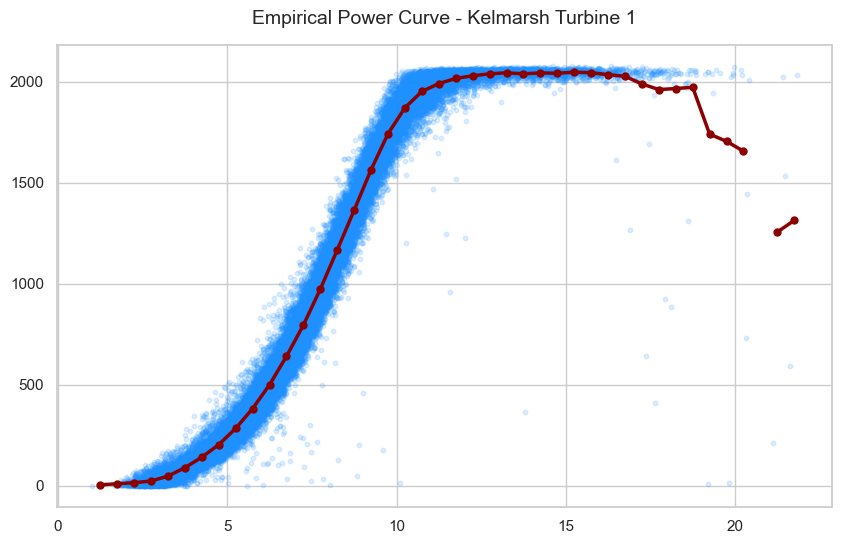

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

#Add root directory
sys.path.append(str(Path.cwd().parent))

from src.data_loader import load_scada_data, filter_operational_data
from src.plotting import plot_empirical_power_curve

#1. Load data
data_file = Path('../data/Turbine_Data_Kelmarsh_1_2020-01-01_-_2021-01-01_228.csv')

try:
    df = load_scada_data(data_file)
    
    # 2. Apply basic operational cleaning (removing negative power spikes)
    # Note: Adjust column names if the Kelmarsh CSV uses different headers (e.g., 'WS', 'P')
    df_clean = filter_operational_data(df, power_col='Power (kW)', wind_speed_col='Wind speed (m/s)')
    
    # 3. Generate and display the power curve
    fig, ax = plot_empirical_power_curve(df_clean, wind_speed_col='Wind speed (m/s)', power_col='Power (kW)', turbine_name='Kelmarsh Turbine 1')
    
    # Optional: Save plot for your GitHub README
    # Path("../notebooks/plots").mkdir(parents=True, exist_ok=True)
    # fig.savefig("../notebooks/plots/power_curve.png", dpi=300)
    
    plt.show()

except Exception as e:
    print(f"Make sure your dataset is placed in the data/ folder. Error details: {e}")
    print(df.columns.tolist())
    